# Pixelwise manipulation - Overlay

**Assumptions**
- We have either unlimited access to the target models api and / or a good enough understanding of it to construct a local surrogate model.
- We already know some images that reach a high score for certain classes.

**Goal**

Given any target image and target class we want to maximize the classes score on the given image.

**General idea**
1. Select target image and target class
2. Choose high-scoring known image according to target class
3. Overlay the target image with the low opacity known image to increase score on the target class

In [17]:
import base64
import io

import requests
from PIL import Image
from matplotlib import pyplot as plt

In [18]:
TARGET_SERVER_URL = "http://localhost:8000"
TARGET_EMOTION = "happiness"
TARGET_IMAGE = Image.open("../examples/angry.png")

# Hardcoded just for proof of concept
KNOWN_IMAGE = Image.open("../examples/happy.png")

In [19]:
session = requests.Session()


def parse_img_tobase64(image):
    buf = io.BytesIO()
    image.save(buf, format="PNG")
    return base64.b64encode(buf.getvalue()).decode("utf-8")


def query_api(image):
    try:
        resp = session.post(
            TARGET_SERVER_URL + "/predict",
            json={"image": parse_img_tobase64(image), "classes": []},
            timeout=30,
        )
        resp.raise_for_status()
        return resp.json()["emotions"]
    except Exception as e:
        print(f"Request failed {e}")
        return None


def plot_images(target_image, known_image, combined_image):
    _, axes = plt.subplots(1, 3, figsize=(25, 5))

    axes[0].imshow(target_image)
    axes[0].set_title("Target image")
    axes[0].axis("off")

    axes[1].imshow(known_image)
    axes[1].set_title("Known image")
    axes[1].axis("off")

    axes[2].imshow(combined_image)
    axes[2].set_title("Combined image")
    axes[2].axis("off")


def pixelwise_manipulation_overlay_attack(target_image, target_emotion, strength=128):
    # Known image needs to be determined somehow.
    combined_image = TARGET_IMAGE.copy()
    edited_known_image = KNOWN_IMAGE.copy()
    edited_known_image.putalpha(strength)
    combined_image.paste(im=edited_known_image, mask=edited_known_image)

    plot_images(target_image, KNOWN_IMAGE, combined_image)

    for image in [target_image, KNOWN_IMAGE, combined_image]:
        print(f"Score {query_api(image)[target_emotion]}")




Score 8.810731665401438e-18
Score 1.0
Score 0.9840474724769592


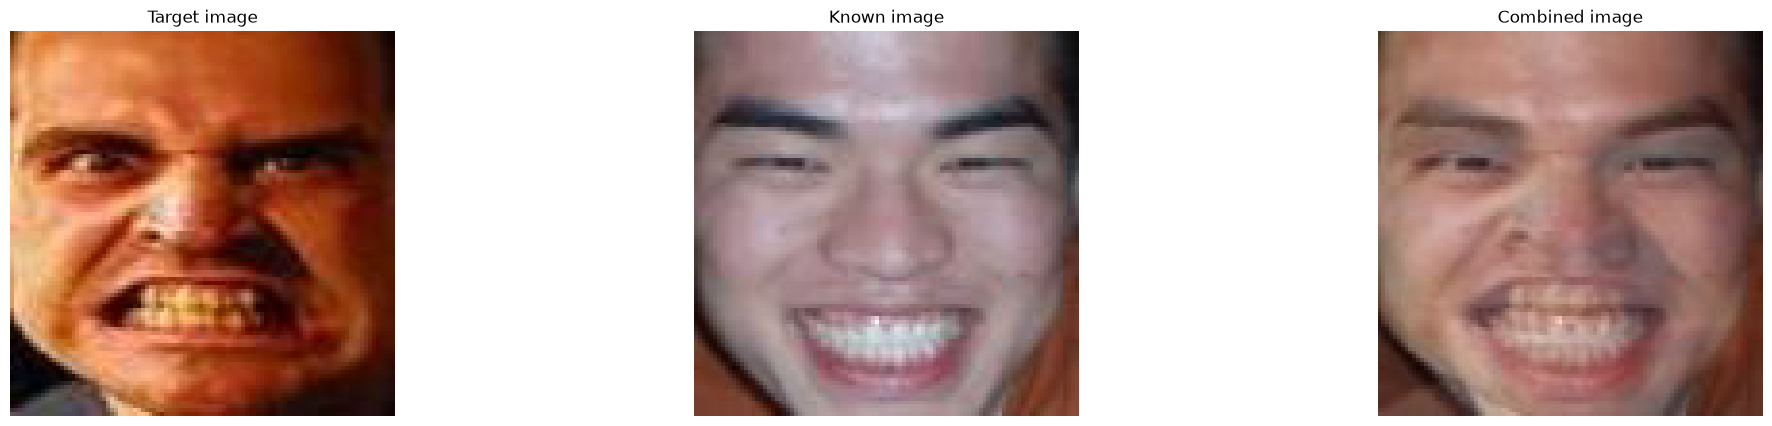

In [24]:
pixelwise_manipulation_overlay_attack(TARGET_IMAGE, TARGET_EMOTION, strength=170)